In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
import nltk
from nltk.util import ngrams
from nltk import pos_tag
from nltk.corpus import stopwords
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, AutoTokenizer
import os 

In [12]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
path = os.getcwd() #path should be Evaluation folder
parent = os.path.join(path, os.pardir) #parent directory
memo_dataset_path = os.path.join(parent, "Data/Memo_Dataset.csv")
df = pd.read_csv(memo_dataset_path)
# Encode trigger as int (if needed)
df['Trigger'] = df['Trigger'].astype(int)

In [15]:
LANGUAGE = 'english' #english, arabic, both

In [16]:
if LANGUAGE == 'english':
    df['text'] = df['Question_eng']
elif LANGUAGE == 'arabic':
    df['text'] = df['Question']
else:
    df['text'] = df['Question_eng'] + ' ||| ' + df['Question']

print("Dataset shape:", df.shape)
print("Class distribution:\n", df['Trigger'].value_counts(normalize=True))

Dataset shape: (13142, 7)
Class distribution:
 Trigger
1    0.584919
0    0.415081
Name: proportion, dtype: float64


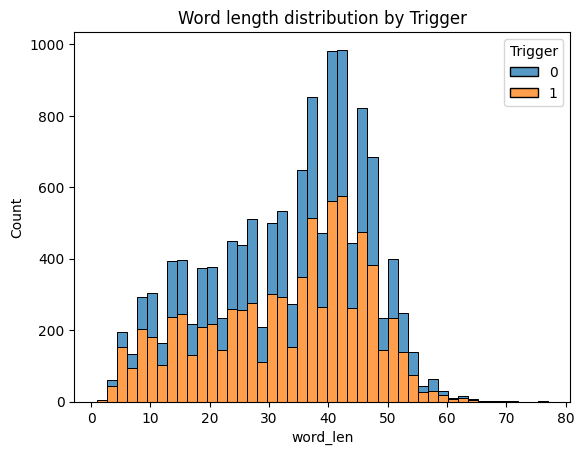

In [17]:
# lengths
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().apply(len)

sns.histplot(df, x='word_len', hue='Trigger', multiple='stack')
plt.title('Word length distribution by Trigger')
plt.show()

In [18]:
def get_top_ngrams(texts, n=1, top_k=20): #ngram analysis
    vec = CountVectorizer(ngram_range=(n,n), stop_words='english' if LANGUAGE in ['english','both'] else None)
    X = vec.fit_transform(texts)
    sum_words = X.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:top_k]

for n in [1,2,3]:
    print(f"Top {n}-grams for triggers:")
    trigger_texts = df[df['Trigger']==1]['text']
    print(get_top_ngrams(trigger_texts, n))
    print(f"Top {n}-grams for non-triggers:")
    non_trigger_texts = df[df['Trigger']==0]['text']
    print(get_top_ngrams(non_trigger_texts, n))

Top 1-grams for triggers:
[('pain', np.int64(3149)), ('suffer', np.int64(1325)), ('feel', np.int64(1231)), ('old', np.int64(1176)), ('years', np.int64(1122)), ('doctor', np.int64(875)), ('treatment', np.int64(838)), ('days', np.int64(801)), ('blood', np.int64(794)), ('does', np.int64(792)), ('severe', np.int64(789)), ('peace', np.int64(741)), ('left', np.int64(721)), ('months', np.int64(705)), ('ago', np.int64(681)), ('time', np.int64(642)), ('right', np.int64(617)), ('month', np.int64(507)), ('like', np.int64(498)), ('year', np.int64(497))]
Top 1-grams for non-triggers:
[('pain', np.int64(1293)), ('normal', np.int64(1161)), ('old', np.int64(1153)), ('years', np.int64(898)), ('days', np.int64(781)), ('feel', np.int64(761)), ('period', np.int64(712)), ('does', np.int64(691)), ('blood', np.int64(676)), ('doctor', np.int64(650)), ('suffer', np.int64(639)), ('peace', np.int64(593)), ('months', np.int64(571)), ('month', np.int64(505)), ('day', np.int64(503)), ('left', np.int64(472)), ('peni

In [19]:
def compute_entropy(texts):
    tokens = ' '.join(texts).split()
    counts = np.array(list(Counter(tokens).values()))
    probs = counts / counts.sum()
    return -np.sum(probs * np.log2(probs))

entropy_trigger = compute_entropy(trigger_texts)
entropy_nontrigger = compute_entropy(non_trigger_texts)
print("Entropy Trigger:", entropy_trigger)
print("Entropy Non-Trigger:", entropy_nontrigger)

Entropy Trigger: 9.366927770503887
Entropy Non-Trigger: 9.353579120351148


In [21]:
lm_model_name = 'gpt2'  # Can swap for arabic LM like 'aubmindlab/aragpt2-base' if installed
tokenizer = AutoTokenizer.from_pretrained(lm_model_name)
model = AutoModelForCausalLM.from_pretrained(lm_model_name)
model.eval()

def compute_ppl(texts):
    ppl_list = []
    for text in texts:
        encodings = tokenizer(text, return_tensors='pt')
        with torch.no_grad():
            outputs = model(**encodings, labels=encodings['input_ids'])
            loss = outputs.loss
        ppl = torch.exp(loss).item()
        ppl_list.append(ppl)
    return np.mean(ppl_list)

if LANGUAGE in ['english','both']:
    ppl_trigger = compute_ppl(trigger_texts[:50])  # sample to save time
    ppl_nontrigger = compute_ppl(non_trigger_texts[:50])
    print("Perplexity Trigger:", ppl_trigger)
    print("Perplexity Non-Trigger:", ppl_nontrigger)

Perplexity Trigger: 103.92306552886963
Perplexity Non-Trigger: 163.33649211883545


In [22]:
#pos tags english
if LANGUAGE in ['english','both']:
    trigger_tokens = [word for sent in trigger_texts for word in nltk.word_tokenize(sent)]
    nontrigger_tokens = [word for sent in non_trigger_texts for word in nltk.word_tokenize(sent)]
    
    trigger_pos = [pos for word,pos in pos_tag(trigger_tokens)]
    nontrigger_pos = [pos for word,pos in pos_tag(nontrigger_tokens)]
    
    trigger_pos_counts = Counter(trigger_pos)
    nontrigger_pos_counts = Counter(nontrigger_pos)
    
    print("Top POS Trigger:", trigger_pos_counts.most_common(10))
    print("Top POS Non-Trigger:", nontrigger_pos_counts.most_common(10))

Top POS Trigger: [('NN', 45324), ('IN', 29260), ('DT', 25786), ('PRP', 22497), ('JJ', 16861), ('CC', 15713), (',', 14588), ('.', 13415), ('NNS', 11198), ('VBP', 11185)]
Top POS Non-Trigger: [('NN', 31819), ('IN', 19862), ('DT', 18908), ('PRP', 17109), ('JJ', 13875), ('CC', 11182), ('.', 10769), (',', 10139), ('VBZ', 8194), ('VBP', 7792)]


Batches: 100%|██████████| 411/411 [00:06<00:00, 63.77it/s] 


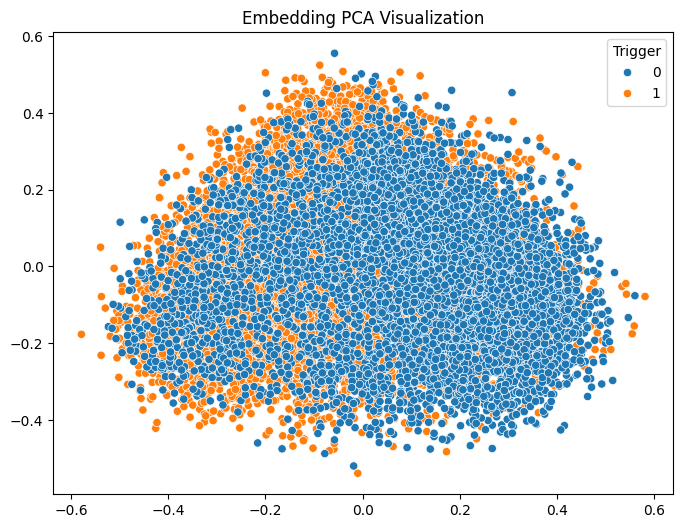

Cluster counts:
 cluster
0    7788
1    5354
Name: count, dtype: int64


In [23]:
#embedding and pca clustering
# Use multilingual embedding if Arabic is involved
if LANGUAGE == 'arabic':
    emb_model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
else:
    emb_model_name = "sentence-transformers/all-MiniLM-L6-v2"

from sentence_transformers import SentenceTransformer
embed_model = SentenceTransformer(emb_model_name)

texts_sample = df['text'].tolist()
embeddings = embed_model.encode(texts_sample, show_progress_bar=True)

# Reduce dimension for visualization
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(8,6))
sns.scatterplot(x=emb_2d[:,0], y=emb_2d[:,1], hue=df['Trigger'])
plt.title('Embedding PCA Visualization')
plt.show()

# Clustering
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(embeddings)
df['cluster'] = labels
print("Cluster counts:\n", df['cluster'].value_counts())

In [24]:
#cross lingual analysis
if LANGUAGE=='both':
    # Compare English vs Arabic similarity
    english_embeddings = embed_model.encode(df['Question_eng'].tolist())
    arabic_embeddings = embed_model.encode(df['Question'].tolist())
    cos_sim = np.sum(english_embeddings * arabic_embeddings, axis=1) / (
        np.linalg.norm(english_embeddings, axis=1) * np.linalg.norm(arabic_embeddings, axis=1)
    )
    df['cross_lingual_cosine'] = cos_sim
    print("Cross-lingual cosine similarity stats:")
    print(df['cross_lingual_cosine'].describe())